In [ ]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\HP\Downloads\Dataset_digital_life_impact_on_habits\social_media_sleep_stress_productivity_11000.csv"
)

print(df.shape)
df.head()

(11000, 10)


,user_id,age,daily_screen_time_hours,social_media_hours,sleep_hours,exercise_minutes,study_work_hours,productivity_score,stress_level,platform
0,1,44,2.39,1.93,8.46,61,3.73,33.86,Low,YouTube
1,2,30,7.22,5.24,7.34,28,6.80,85.32,Low,YouTube
2,3,23,2.56,4.64,4.69,8,4.47,60.07,High,YouTube
3,4,36,8.75,4.89,5.05,53,9.53,36.46,Medium,LinkedIn
4,5,34,10.96,2.77,7.12,83,7.01,32.93,Medium,Instagram


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
X = df["sleep_hours"].tolist()
Y = df["productivity_score"].tolist()

print("Total observations:", len(X))

Total observations: 11000


In [ ]:
import random

# Keep only complete X-Y pairs
pairs = []

for x, y in zip(X, Y):
    if pd.notna(x) and pd.notna(y):
        pairs.append((float(x), float(y)))

# Shuffle reproducibly
random.seed(42)
random.shuffle(pairs)

split_index = int(0.8 * len(pairs))

train_data = pairs[:split_index]
test_data = pairs[split_index:]

X_train = [row[0] for row in train_data]
Y_train = [row[1] for row in train_data]

X_test = [row[0] for row in test_data]
Y_test = [row[1] for row in test_data]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 8800
Testing observations: 2200


In [9]:
n = len(X_train)

mean_X = sum(X_train) / n
mean_Y = sum(Y_train) / n

print("Mean sleep hours:", mean_X)
print("Mean productivity:", mean_Y)

Mean sleep hours: 5.985910227272727
Mean productivity: 50.40452159090909


In [10]:
numerator = 0
denominator = 0

for i in range(n):
    numerator += (
        (X_train[i] - mean_X) *
        (Y_train[i] - mean_Y)
    )

    denominator += (
        (X_train[i] - mean_X) ** 2
    )

if denominator == 0:
    raise ValueError("Cannot fit regression: X has no variation.")

b1 = numerator / denominator

print("Slope:", b1)

Slope: 0.17377917822658753


In [12]:
b0 = mean_Y - b1 * mean_X

print("Intercept:", b0)

Intercept: 49.364295030675514


In [ ]:
print(f"Regression equation: Y = {b0:.4f} + ({b1:.4f})X")

Regression equation: Y = 49.364295030675514 + (0.17377917822658753)X


In [14]:
Y_pred = []

for x in X_test:
    prediction = b0 + b1 * x
    Y_pred.append(prediction)

print("First five predictions:")

for i in range(5):
    print(
        "Sleep:", X_test[i],
        "Actual:", Y_test[i],
        "Predicted:", round(Y_pred[i], 2)
    )

First five predictions:
Sleep: 6.75 Actual: 16.73 Predicted: 50.54
Sleep: 6.71 Actual: 34.84 Predicted: 50.53
Sleep: 6.24 Actual: 70.49 Predicted: 50.45
Sleep: 7.85 Actual: 54.97 Predicted: 50.73
Sleep: 6.08 Actual: 52.25 Predicted: 50.42


In [15]:
sleep = 7

predicted_productivity = b0 + b1 * sleep

print(
    "Predicted productivity:",
    round(predicted_productivity, 2)
)

Predicted productivity: 50.58


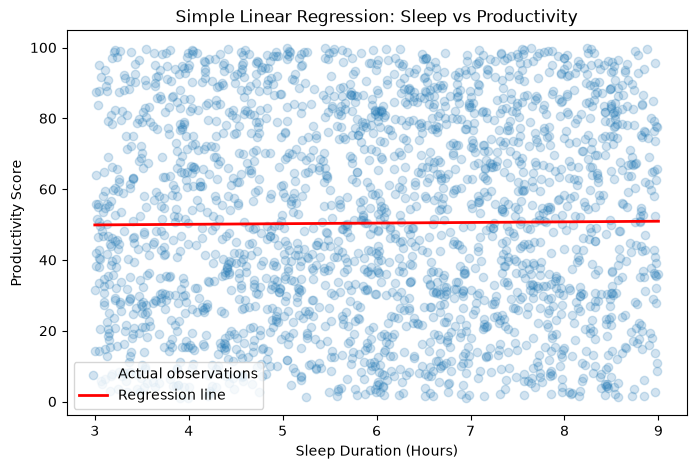

In [ ]:
plt.figure(figsize=(8, 5))
# Actual test observations
plt.scatter(
    X_test,
    Y_test,
    alpha=0.2,
    label="Actual observations"
)

# Regression line
x_line = sorted(X_test)
y_line = [b0 + b1 * x for x in x_line]

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Regression line"
)

plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Productivity Score")
plt.title("Simple Linear Regression: Sleep vs Productivity")

plt.legend()
plt.show()